In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from wordcloud import WordCloud

import warnings
warnings.filterwarnings('ignore')

print("All libraries imported successfully!")

All libraries imported successfully!


In [4]:
from google.colab import files

uploaded = files.upload()

Saving zomato.csv to zomato (1).csv


In [6]:
import io

filename = list(uploaded.keys())[0]

df = pd.read_csv(io.BytesIO(uploaded[filename]))

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [7]:
df.head()

,address,name,online_order,book_table,rate,votes,phone,location,rest_type,dish_liked,cuisines,approx_cost(for two people),listed_in(type)
0,"942, 21st Main Road, 2nd Stage, Banashankari, ...",Jalsa,Yes,Yes,4.1/5,775,080 42297555\r\n+91 9743772233,Banashankari,Casual Dining,"Pasta, Lunch Buffet, Masala Papad, Paneer Laja...","North Indian, Mughlai, Chinese",800,Buffet
1,"2nd Floor, 80 Feet Road, Near Big Bazaar, 6th ...",Spice Elephant,Yes,No,4.1/5,787,080 41714161,Banashankari,Casual Dining,"Momos, Lunch Buffet, Chocolate Nirvana, Thai G...","Chinese, North Indian, Thai",800,Buffet
2,"1112, Next to KIMS Medical College, 17th Cross...",San Churro Cafe,Yes,No,3.8/5,918,+91 9663487993,Banashankari,"Cafe, Casual Dining","Churros, Cannelloni, Minestrone Soup, Hot Choc...","Cafe, Mexican, Italian",800,Buffet
3,"1st Floor, Annakuteera, 3rd Stage, Banashankar...",Addhuri Udupi Bhojana,No,No,3.7/5,88,+91 9620009302,Banashankari,Quick Bites,Masala Dosa,"South Indian, North Indian",300,Buffet
4,"10, 3rd Floor, Lakshmi Associates, Gandhi Baza...",Grand Village,No,No,3.8/5,166,+91 8026612447\r\n+91 9901210005,Basavanagudi,Casual Dining,"Panipuri, Gol Gappe","North Indian, Rajasthani",600,Buffet


In [8]:
df.shape

(56252, 13)

In [9]:
df.columns.tolist()

['address',
 'name',
 'online_order',
 'book_table',
 'rate',
 'votes',
 'phone',
 'location',
 'rest_type',
 'dish_liked',
 'cuisines',
 'approx_cost(for two people)',
 'listed_in(type)']

In [10]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 56252 entries, 0 to 56251
Data columns (total 13 columns):
 #   Column                       Non-Null Count  Dtype 
---  ------                       --------------  ----- 
 0   address                      56235 non-null  object
 1   name                         56236 non-null  object
 2   online_order                 56233 non-null  object
 3   book_table                   56194 non-null  object
 4   rate                         48414 non-null  object
 5   votes                        56174 non-null  object
 6   phone                        54956 non-null  object
 7   location                     56126 non-null  object
 8   rest_type                    55914 non-null  object
 9   dish_liked                   28027 non-null  object
 10  cuisines                     56049 non-null  object
 11  approx_cost(for two people)  55731 non-null  object
 12  listed_in(type)              51642 non-null  object
dtypes: object(13)
memory usage: 5.6

In [11]:
df.isnull().sum()

,0
address,17
name,16
online_order,19
book_table,58
rate,7838
votes,78
phone,1296
location,126
rest_type,338
dish_liked,28225


In [12]:
df.duplicated().sum()

np.int64(15703)

In [13]:
df.describe(include='all')

,address,name,online_order,book_table,rate,votes,phone,location,rest_type,dish_liked,cuisines,approx_cost(for two people),listed_in(type)
count,56235,56236,56233,56194,48414,56174,54956,56126,55914,28027,56049,55731,51642
unique,13397,11914,2639,2902,2877,5195,17712,2920,2961,8067,5553,2879,2783
top,('Rated 4.0',('Rated 4.0',Yes,No,NEW,0,('Rated 4.0',BTM,Quick Bites,('Rated 4.0',North Indian,300,Delivery
freq,942,300,30444,45268,2208,10027,412,5125,19132,407,2913,7576,24317


In [14]:
print("Duplicates before cleaning:", df.duplicated().sum())

df = df.drop_duplicates().copy()

print("Duplicates after cleaning:", df.duplicated().sum())

Duplicates before cleaning: 15703
Duplicates after cleaning: 0


In [15]:
df.columns = (
    df.columns
    .str.strip()
    .str.lower()
    .str.replace(" ", "_")
)

print(df.columns.tolist())

['address', 'name', 'online_order', 'book_table', 'rate', 'votes', 'phone', 'location', 'rest_type', 'dish_liked', 'cuisines', 'approx_cost(for_two_people)', 'listed_in(type)']


In [16]:
text_columns = df.select_dtypes(include=['object', 'string']).columns

for col in text_columns:
    df[col] = df[col].apply(
        lambda x: x.strip() if isinstance(x, str) else x
    )

print("Text cleaning completed!")

Text cleaning completed!


In [17]:
df.isnull().sum()

,0
address,2
name,1
online_order,4
book_table,38
rate,4145
votes,58
phone,808
location,98
rest_type,251
dish_liked,18226


In [18]:
# Clean restaurant ratings

df['rate'] = (
    df['rate']
    .astype('string')
    .str.extract(r'(\d+(?:\.\d+)?)')[0]
)

df['rate'] = pd.to_numeric(df['rate'], errors='coerce')

# Keep only valid ratings between 0 and 5
df.loc[~df['rate'].between(0, 5), 'rate'] = np.nan

print("Rating column cleaned successfully!")

print(df['rate'].head(10))

Rating column cleaned successfully!
0     4.1
1     4.1
2     3.8
3     3.7
4     3.8
5     3.8
6     3.6
7     4.6
8     4.0
9    <NA>
Name: rate, dtype: Float64


In [19]:
# Clean approximate cost for two people

df['approx_cost(for_two_people)'] = (
    df['approx_cost(for_two_people)']
    .astype('string')
    .str.replace(',', '', regex=False)
    .str.replace('₹', '', regex=False)
    .str.strip()
)

df['approx_cost(for_two_people)'] = pd.to_numeric(
    df['approx_cost(for_two_people)'],
    errors='coerce'
)

print("Restaurant prices cleaned successfully!")

print(df['approx_cost(for_two_people)'].head(10))

Restaurant prices cleaned successfully!
0     800
1     800
2     800
3     300
4     600
5     600
6     800
7     600
8     700
9    <NA>
Name: approx_cost(for_two_people), dtype: Int64


In [20]:
# Convert votes into numeric values

df['votes'] = pd.to_numeric(
    df['votes'],
    errors='coerce'
)

print("Votes column cleaned successfully!")

print(df['votes'].head(10))

Votes column cleaned successfully!
0     775.0
1     787.0
2     918.0
3      88.0
4     166.0
5     286.0
6       8.0
7    2556.0
8     324.0
9       NaN
Name: votes, dtype: float64


In [21]:
# Handle missing categorical values

categorical_columns = [
    'location',
    'rest_type',
    'cuisines',
    'online_order',
    'book_table',
    'dish_liked'
]

for col in categorical_columns:
    df[col] = df[col].fillna('Unknown')

# Missing votes are kept as missing
# because an unknown vote count is not necessarily zero.

print("Missing values handled!")

print(df.isnull().sum())

Missing values handled!
address                           2
name                              1
online_order                      0
book_table                        0
rate                           8311
votes                          4147
phone                           808
location                          0
rest_type                         0
dish_liked                        0
cuisines                          0
approx_cost(for_two_people)    4366
listed_in(type)                2907
dtype: int64


In [22]:
df.to_csv('zomato_cleaned.csv', index=False)

print("Cleaned dataset saved successfully!")

Cleaned dataset saved successfully!


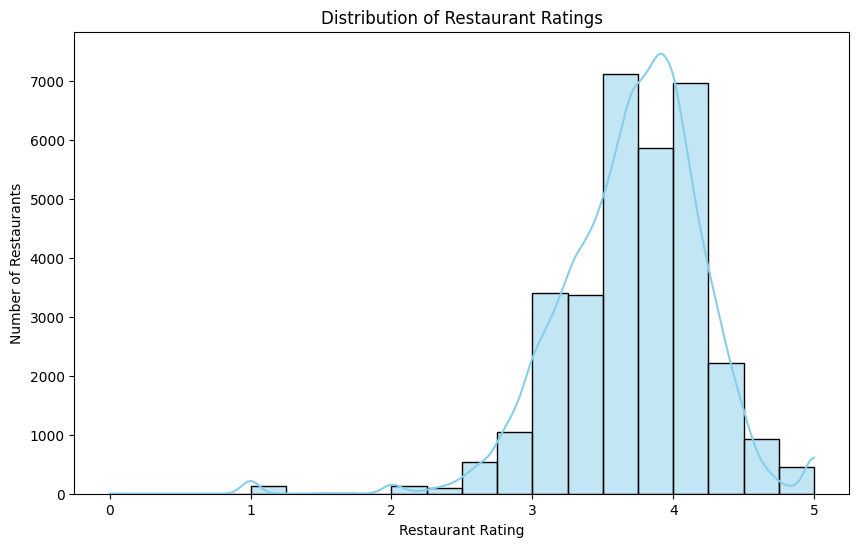

In [23]:
plt.figure(figsize=(10, 6))

sns.histplot(
    df['rate'].dropna(),
    bins=20,
    kde=True,
    color='skyblue'
)

plt.title('Distribution of Restaurant Ratings')
plt.xlabel('Restaurant Rating')
plt.ylabel('Number of Restaurants')

plt.show()

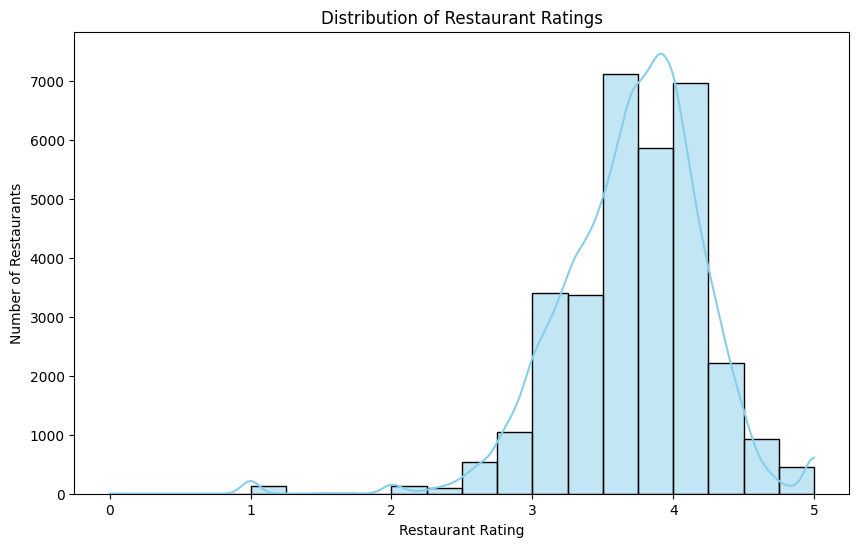

In [24]:
plt.figure(figsize=(10, 6))

sns.histplot(
    df['rate'].dropna(),
    bins=20,
    kde=True,
    color='skyblue'
)

plt.title('Distribution of Restaurant Ratings')
plt.xlabel('Restaurant Rating')
plt.ylabel('Number of Restaurants')

plt.show()

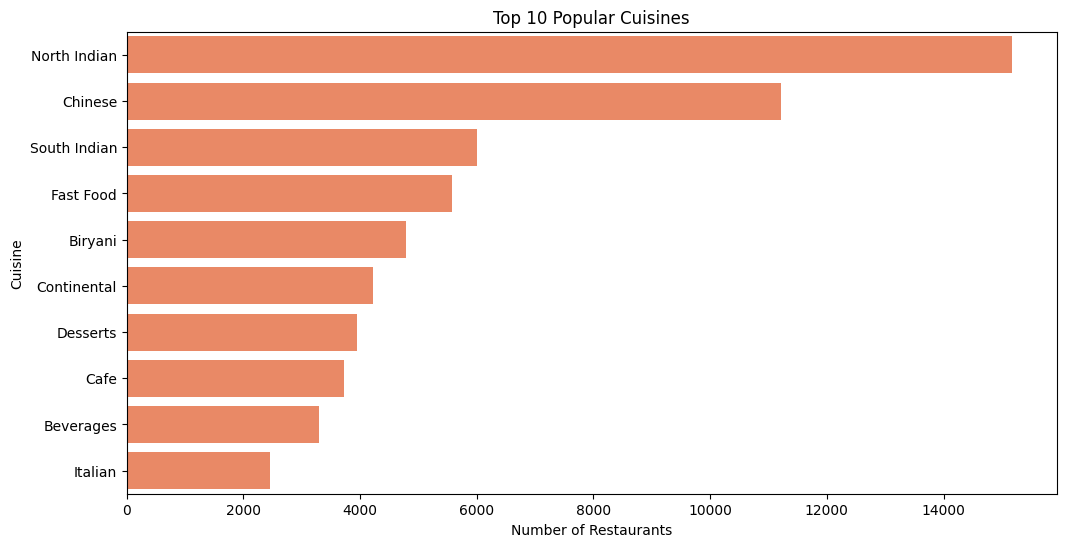

In [25]:
cuisine_data = (
    df['cuisines']
    .dropna()
    .str.split(',')
    .explode()
    .str.strip()
)

cuisine_data = cuisine_data[
    (cuisine_data != 'Unknown') &
    (cuisine_data != '')
]

top_cuisines = cuisine_data.value_counts().head(10)

plt.figure(figsize=(12, 6))

sns.barplot(
    x=top_cuisines.values,
    y=top_cuisines.index,
    color='coral'
)

plt.title('Top 10 Popular Cuisines')
plt.xlabel('Number of Restaurants')
plt.ylabel('Cuisine')

plt.show()

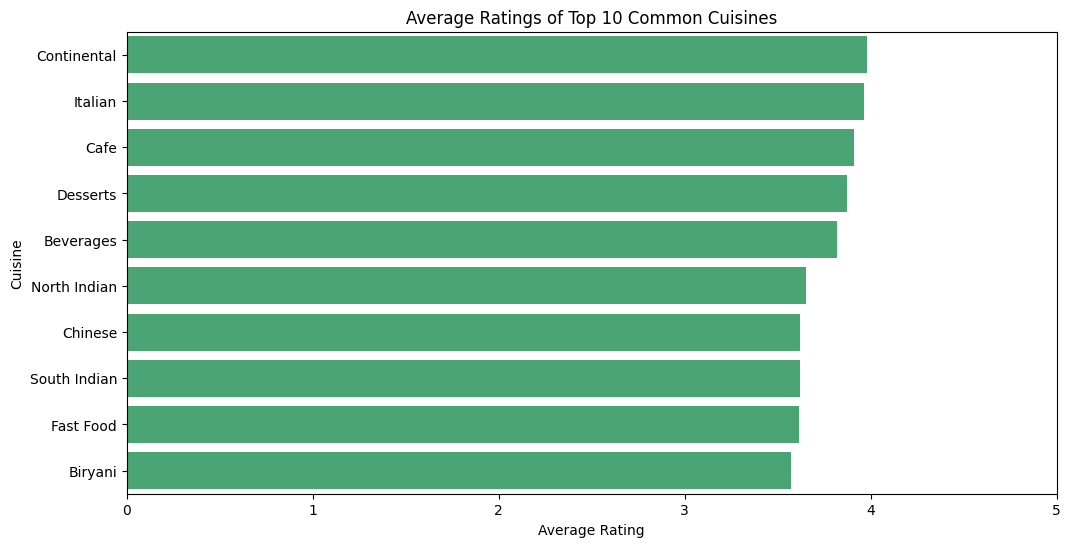

In [26]:
cuisine_ratings = df[['cuisines', 'rate']].copy()

cuisine_ratings = cuisine_ratings.dropna(subset=['rate'])

cuisine_ratings['cuisines'] = (
    cuisine_ratings['cuisines'].str.split(',')
)

cuisine_ratings = cuisine_ratings.explode('cuisines')

cuisine_ratings['cuisines'] = (
    cuisine_ratings['cuisines'].str.strip()
)

cuisine_ratings = cuisine_ratings[
    cuisine_ratings['cuisines'] != 'Unknown'
]

cuisine_summary = (
    cuisine_ratings.groupby('cuisines')['rate']
    .agg(['mean', 'count'])
)

# Focus on the 10 most common rated cuisines
top_rated_cuisines = (
    cuisine_summary
    .sort_values('count', ascending=False)
    .head(10)
    .sort_values('mean', ascending=False)
)

plt.figure(figsize=(12, 6))

sns.barplot(
    x=top_rated_cuisines['mean'],
    y=top_rated_cuisines.index,
    color='mediumseagreen'
)

plt.title('Average Ratings of Top 10 Common Cuisines')
plt.xlabel('Average Rating')
plt.ylabel('Cuisine')
plt.xlim(0, 5)

plt.show()

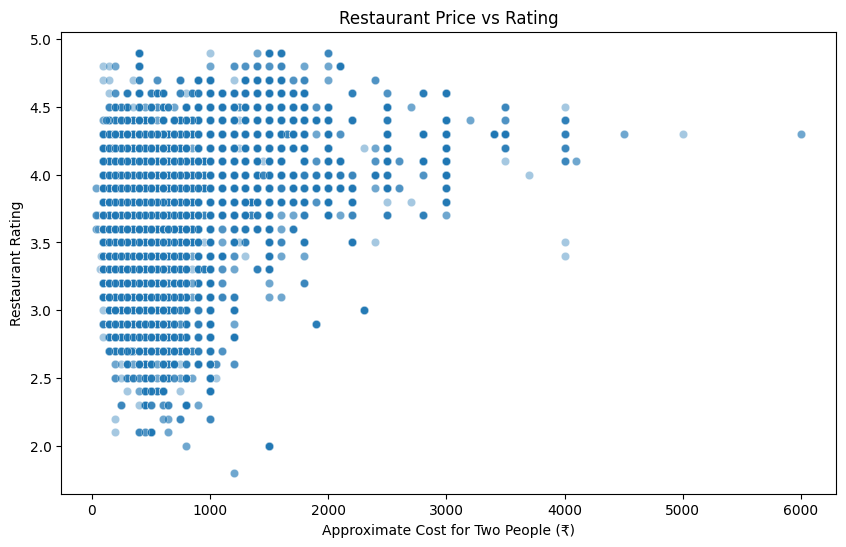

Price vs Rating Correlation: 0.385


In [27]:
price_rating = df[
    ['approx_cost(for_two_people)', 'rate']
].dropna()

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=price_rating,
    x='approx_cost(for_two_people)',
    y='rate',
    alpha=0.4
)

plt.title('Restaurant Price vs Rating')
plt.xlabel('Approximate Cost for Two People (₹)')
plt.ylabel('Restaurant Rating')

plt.show()

correlation = price_rating[
    'approx_cost(for_two_people)'
].corr(price_rating['rate'])

print("Price vs Rating Correlation:", round(correlation, 3))

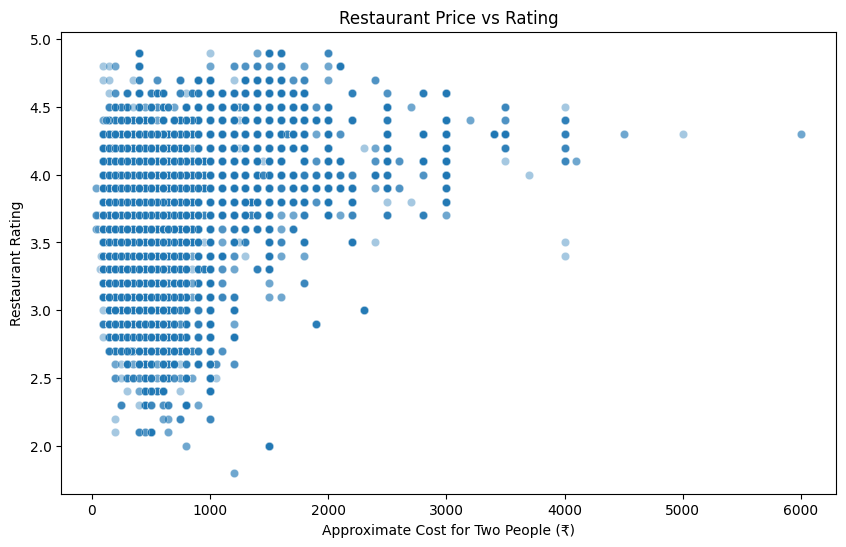

Price vs Rating Correlation: 0.385


In [28]:
price_rating = df[
    ['approx_cost(for_two_people)', 'rate']
].dropna()

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=price_rating,
    x='approx_cost(for_two_people)',
    y='rate',
    alpha=0.4
)

plt.title('Restaurant Price vs Rating')
plt.xlabel('Approximate Cost for Two People (₹)')
plt.ylabel('Restaurant Rating')

plt.show()

correlation = price_rating[
    'approx_cost(for_two_people)'
].corr(price_rating['rate'])

print("Price vs Rating Correlation:", round(correlation, 3))

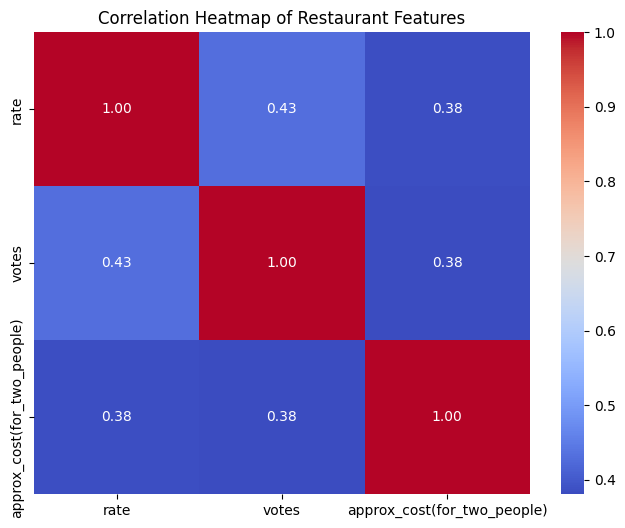

In [29]:
numeric_data = df[
    ['rate', 'votes', 'approx_cost(for_two_people)']
].copy()

correlation_matrix = numeric_data.corr()

plt.figure(figsize=(8, 6))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Correlation Heatmap of Restaurant Features')

plt.show()

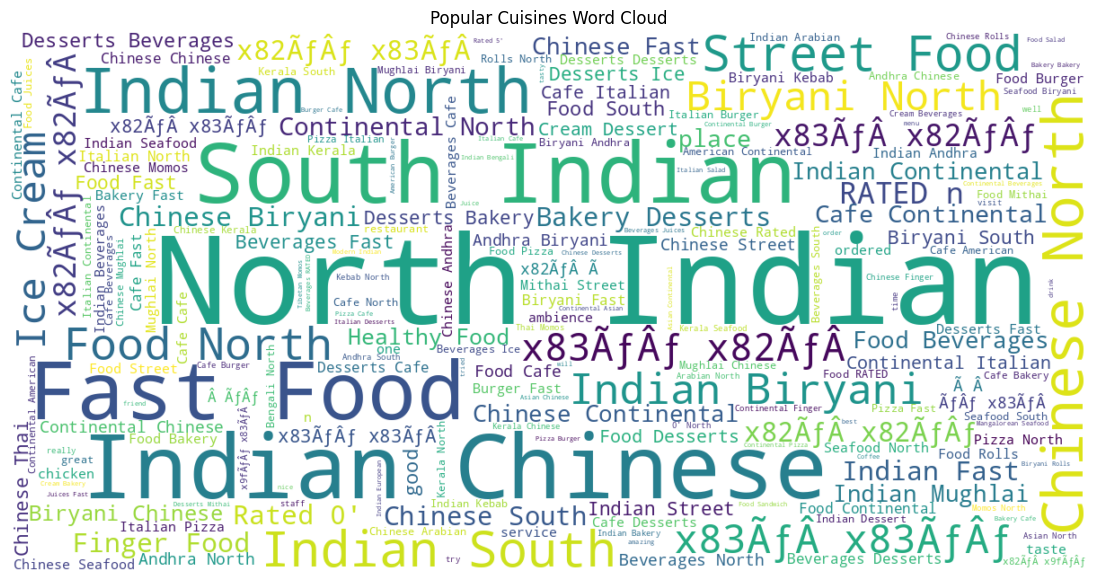

In [30]:
from wordcloud import WordCloud

cuisine_text = ' '.join(cuisine_data.astype(str))

wordcloud = WordCloud(
    width=1200,
    height=600,
    background_color='white',
    colormap='viridis'
).generate(cuisine_text)

plt.figure(figsize=(14, 7))

plt.imshow(wordcloud, interpolation='bilinear')
plt.axis('off')

plt.title('Popular Cuisines Word Cloud')

plt.show()

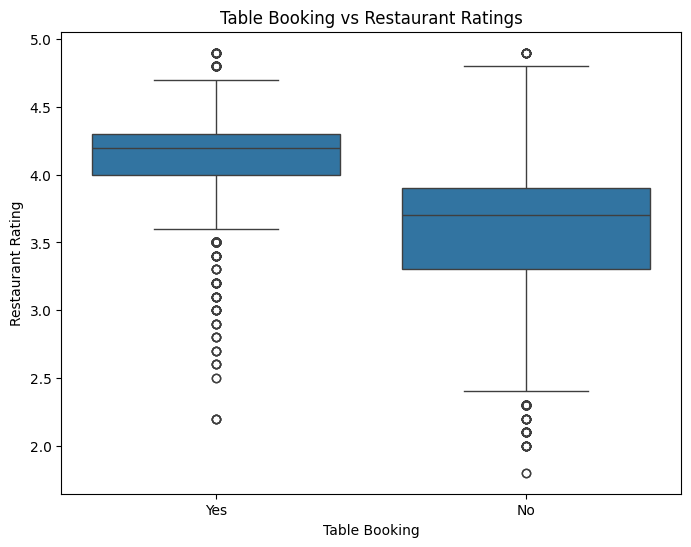

In [31]:
plt.figure(figsize=(8, 6))

sns.boxplot(
    data=df,
    x='book_table',
    y='rate',
    order=['Yes', 'No']
)

plt.title('Table Booking vs Restaurant Ratings')
plt.xlabel('Table Booking')
plt.ylabel('Restaurant Rating')

plt.show()

In [32]:
import os

os.makedirs('zomato_visualizations', exist_ok=True)

print("Visualization folder created!")

Visualization folder created!


In [33]:
from google.colab import files

files.download('zomato_cleaned.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [34]:
import os

os.makedirs('zomato_visualizations', exist_ok=True)

# Save the cuisine word cloud
wordcloud.to_file('zomato_visualizations/cuisine_wordcloud.png')

print("Word cloud saved successfully!")

Word cloud saved successfully!
